In [5]:

import numpy as np
import openpyxl

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
from pathlib import Path
warnings.filterwarnings('ignore')

data_path = Path("output") / "ApexPlanet_Cleaned_Dataset.xlsx"
if not data_path.is_file():
    data_path = Path("..") / data_path

df = pd.read_excel(data_path, engine='openpyxl')

In [6]:
# Numerical summary
display(df.describe())

# Mean
print(df.mean(numeric_only=True))

# Median
print(df.median(numeric_only=True))

# Mode
print(df.mode().head())

# Standard deviation
print(df.std(numeric_only=True))

# Variance
print(df.var(numeric_only=True))

,Order_Date,Age,Quantity,Unit_Price,Total_Sales,Unnamed: 12,Calculated_Sales,Year,Month,Day,Total_Revenue
count,1000,1000.000000,1000.000000,1000.000000,1000.000000,27.0,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,2025-07-03 11:19:40.800000,41.353000,5.435000,25486.783410,139399.439650,1.0,139399.439650,2025.005000,6.518000,15.605000,139399.439650
min,2025-01-01 00:00:00,18.000000,1.000000,145.780000,437.340000,1.0,437.340000,2025.000000,1.000000,1.000000,437.340000
25%,2025-03-30 18:00:00,30.000000,3.000000,13895.722500,47066.632500,1.0,47066.632500,2025.000000,3.000000,8.000000,47066.632500
50%,2025-07-01 00:00:00,41.000000,5.000000,25398.740000,108594.025000,1.0,108594.025000,2025.000000,6.000000,16.000000,108594.025000
75%,2025-10-07 06:00:00,53.000000,8.000000,37512.382500,203722.882500,1.0,203722.882500,2025.000000,10.000000,23.000000,203722.882500
max,2026-01-01 00:00:00,65.000000,10.000000,49997.530000,493677.500000,1.0,493677.500000,2026.000000,12.000000,31.000000,493677.500000
std,NaN,13.683626,2.838632,14179.402361,114100.051546,0.0,114100.051546,0.070569,3.498845,8.772795,114100.051546


Age                     41.35300
Quantity                 5.43500
Unit_Price           25486.78341
Total_Sales         139399.43965
Unnamed: 12              1.00000
Calculated_Sales    139399.43965
Sales_Mismatch           0.00000
Year                  2025.00500
Month                    6.51800
Day                     15.60500
Total_Revenue       139399.43965
dtype: float64
Age                     41.000
Quantity                 5.000
Unit_Price           25398.740
Total_Sales         108594.025
Unnamed: 12              1.000
Calculated_Sales    108594.025
Sales_Mismatch           0.000
Year                  2025.000
Month                    6.000
Day                     16.000
Total_Revenue       108594.025
dtype: float64
    Order_ID Order_Date Customer_ID Customer_Name   Age Gender   City Product  \
0  ORD100050 2025-04-16    CUST2515  Customer_359  41.0   Male  Patna  Mobile   
1        NaN        NaT         NaN           NaN   NaN    NaN    NaN     NaN   
2        NaN        NaT

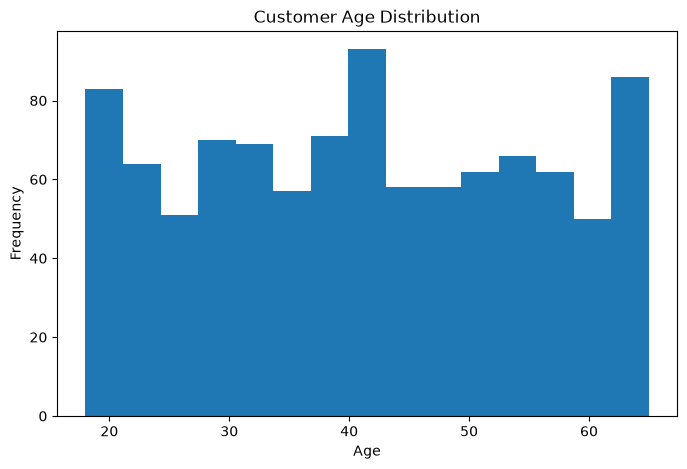

In [7]:
plt.figure(figsize=(8, 5))

plt.hist(df['Age'], bins=15)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

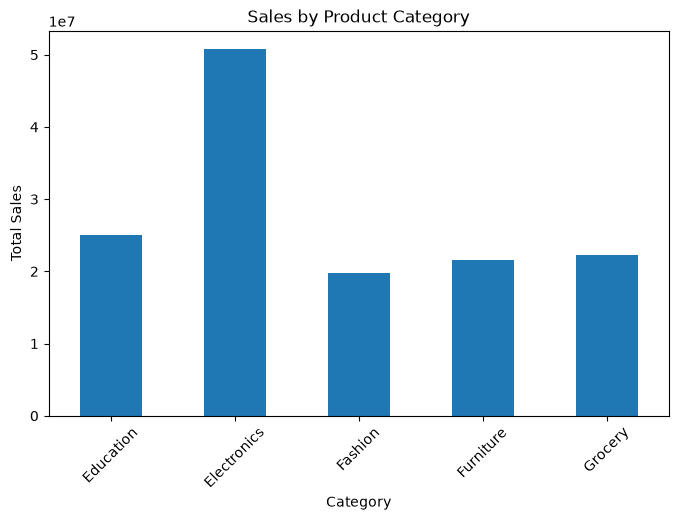

In [8]:
df.groupby('Category')['Total_Sales'].sum().plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title("Sales by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.show()

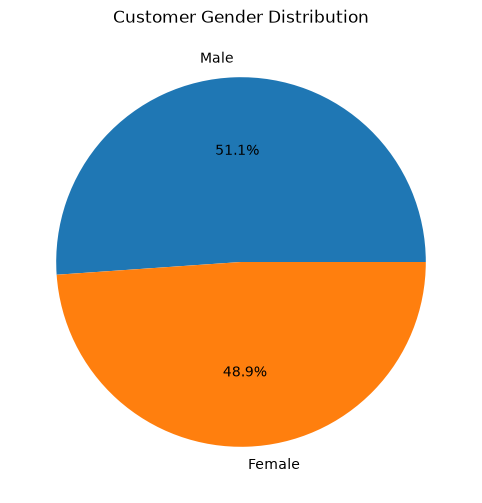

In [9]:
df['Gender'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(6, 6)
)

plt.title("Customer Gender Distribution")
plt.ylabel("")

plt.show()

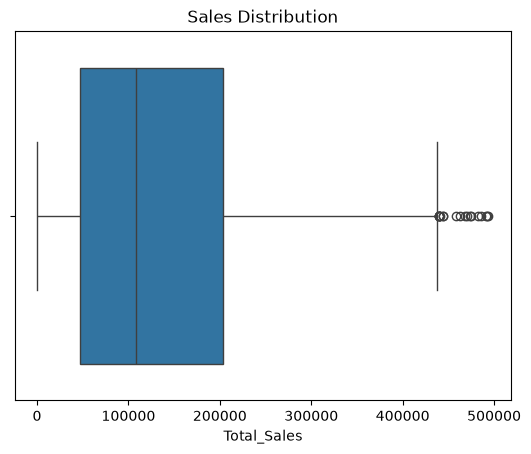

In [10]:
sns.boxplot(x=df['Total_Sales'])

plt.title("Sales Distribution")
plt.show()

In [14]:
import sqlite3
conn = sqlite3.connect("apexplanet_sales.db")

df.to_sql(
    "sales",
    conn,
    if_exists="replace",
    index=False
)

print("Dataset successfully loaded into SQLite!")

Dataset successfully loaded into SQLite!
